In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score,classification_report,accuracy_score,confusion_matrix

from sklearn.preprocessing import StandardScaler

In [16]:
print(dir(preprocessing))

['Binarizer', 'FunctionTransformer', 'KBinsDiscretizer', 'KernelCenterer', 'LabelBinarizer', 'LabelEncoder', 'MaxAbsScaler', 'MinMaxScaler', 'MultiLabelBinarizer', 'Normalizer', 'OneHotEncoder', 'OrdinalEncoder', 'PolynomialFeatures', 'PowerTransformer', 'QuantileTransformer', 'RobustScaler', 'SplineTransformer', 'StandardScaler', 'TargetEncoder', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_csr_polynomial_expansion', '_data', '_discretization', '_encoders', '_function_transformer', '_label', '_polynomial', '_target_encoder', '_target_encoder_fast', 'add_dummy_feature', 'binarize', 'label_binarize', 'maxabs_scale', 'minmax_scale', 'normalize', 'power_transform', 'quantile_transform', 'robust_scale', 'scale']


In [7]:
df=pd.read_csv("UniversalBank.csv")
print(df.head(5))

   ID  Age  Experience  Income  ZIP Code  Family  CCAvg  Education  Mortgage  \
0   1   25           1      49     91107       4    1.6          1         0   
1   2   45          19      34     90089       3    1.5          1         0   
2   3   39          15      11     94720       1    1.0          1         0   
3   4   35           9     100     94112       1    2.7          2         0   
4   5   35           8      45     91330       4    1.0          2         0   

   Personal Loan  Securities Account  CD Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0       0           0  
4              0                   0           0       0           1  


In [8]:
# remove unnecessary columns
df=df.drop('ID',axis=1)

In [9]:
print(df.head(5))


   Age  Experience  Income  ZIP Code  Family  CCAvg  Education  Mortgage  \
0   25           1      49     91107       4    1.6          1         0   
1   45          19      34     90089       3    1.5          1         0   
2   39          15      11     94720       1    1.0          1         0   
3   35           9     100     94112       1    2.7          2         0   
4   35           8      45     91330       4    1.0          2         0   

   Personal Loan  Securities Account  CD Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0       0           0  
4              0                   0           0       0           1  


In [10]:
df.dtypes

Age                     int64
Experience              int64
Income                  int64
ZIP Code                int64
Family                  int64
CCAvg                 float64
Education               int64
Mortgage                int64
Personal Loan           int64
Securities Account      int64
CD Account              int64
Online                  int64
CreditCard              int64
dtype: object

In [13]:
df.isnull().sum()
df.columns=df.columns.str.strip()

In [12]:
df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937913,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747666,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [22]:
X=df.drop(columns=['CreditCard','ZIP Code'])
y=df['CreditCard']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

model=LogisticRegression()

model.fit(x_train,y_train)

y_pred=model.predict(x_test)


In [26]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.7755102040816326
classification_report :               precision    recall  f1-score   support

           0       0.73      0.98      0.84       706
           1       0.78      0.13      0.22       294

    accuracy                           0.73      1000
   macro avg       0.75      0.56      0.53      1000
weighted avg       0.74      0.73      0.66      1000

 accuracy_score:  0.733
[[695  11]
 [256  38]]


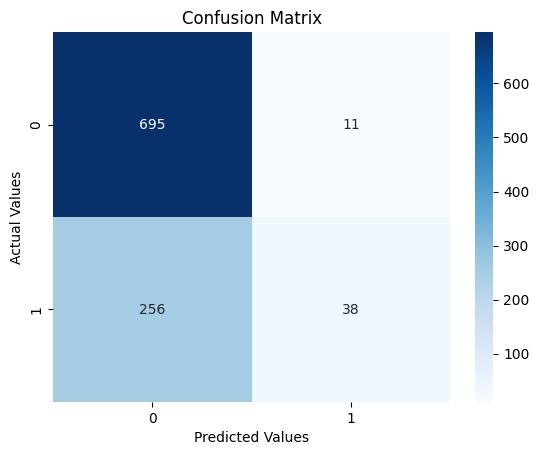

In [27]:
sns.heatmap(cn,cmap="Blues",annot=True,fmt='g',linecolor="white")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Confusion Matrix")
plt.show()

In [47]:
#Social_Network_Ads.csv

df=pd.read_csv("Social_Network_Ads.csv")
print(df.head(5))

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0


In [48]:
df.isnull().sum()
df.columns=df.columns.str.strip()

In [49]:
df=df.dropna(subset=['Purchased'])

In [50]:
df.dtypes

User ID             int64
Gender             object
Age                 int64
EstimatedSalary     int64
Purchased           int64
dtype: object

In [51]:
df['Gender']=df['Gender'].map({
    'Male':0,
    'Female':1
})

In [52]:
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,0,19,19000,0
1,15810944,0,35,20000,0
2,15668575,1,26,43000,0
3,15603246,1,27,57000,0
4,15804002,0,19,76000,0
...,...,...,...,...,...
395,15691863,1,46,41000,1
396,15706071,0,51,23000,1
397,15654296,1,50,20000,1
398,15755018,0,36,33000,0


In [53]:
df=df.drop('User ID',axis=1)

In [59]:
X=df.drop(columns=['Purchased'])
y=df['Purchased']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.24,random_state=42)

# scaling
scaler=StandardScaler()
x_test_original=x_test
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

model=LogisticRegression()
model.fit(x_train,y_train)

y_pred=model.predict(x_test)

In [60]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.9259259259259259
classification_report :               precision    recall  f1-score   support

           0       0.87      0.97      0.92        62
           1       0.93      0.74      0.82        34

    accuracy                           0.89        96
   macro avg       0.90      0.85      0.87        96
weighted avg       0.89      0.89      0.88        96

 accuracy_score:  0.8854166666666666
[[60  2]
 [ 9 25]]


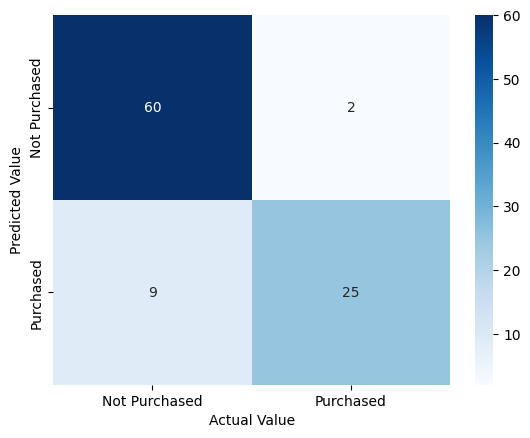

In [61]:
sns.heatmap(cn,cmap="Blues",annot=True,fmt='g',xticklabels=['Not Purchased','Purchased'],yticklabels=['Not Purchased','Purchased'])
plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.show()

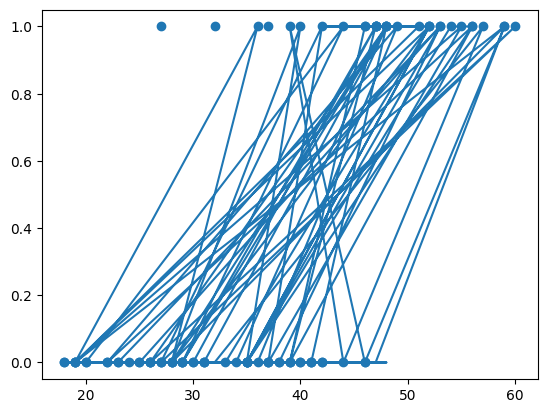

In [62]:
plt.scatter(x_test_original['Age'],y_test,label="Actual")
plt.plot(x_test_original['Age'],y_pred,label="Predicted")
plt.show()